# 02 · Análisis de calidad temporal (ítem C del artículo)

**Entrada:** `data/processed/<estación>/<estación>_horario.csv` (generado por el notebook 01).

**Salida:** `data/clean/<estación>/<estación>_inventario_huecos.csv`, el catálogo de todos los huecos de cada variable.

## Qué dice el artículo (ítem C)

> *"Antes de la imputación de datos, el marco se encargó de caracterizar la estructura temporal de cada estación de forma independiente. La frecuencia de muestreo dominante se estableció como la moda estadística de las diferencias entre marcas de tiempo consecutivas. Se construyó una grilla completa […] entre el registro más antiguo y el más reciente de cada estación. Los gaps individuales (intervalo entre observaciones consecutivas que superara 1,5 veces la frecuencia dominante) se catalogan con hora de inicio, duración y un conteo estimado de registros faltantes. Los gaps se clasificaron en tres categorías: cortos (hasta 60 min), medios (entre 60 min y 24 h) y largos (más de 24 h)."*

## Cómo se aplica aquí y qué se adapta

| Paso del artículo | Aplicación en este notebook |
|---|---|
| Frecuencia dominante = moda de las diferencias | Se calcula; tras el notebook 01 debe dar **60 min** |
| Grilla completa entre el primer y el último registro | Ya se construyó en el notebook 01 (una fila por hora) |
| Gap = separación mayor a 1,5 × frecuencia dominante | Con grilla horaria equivale a **una o más horas seguidas sin dato**. Se cataloga **por variable**, porque una hora puede tener lluvia pero no nivel |
| Catálogo con inicio, duración y registros faltantes | Se genera y se guarda en CSV |
| Categorías: corto ≤ 60 min, medio 60 min–24 h, largo > 24 h | **Adaptado:** corto **≤ 6 h**, medio **6–24 h**, largo **> 24 h** (explicación abajo) |

**¿Por qué cambia el límite de "corto"?** El artículo trabaja con datos cada 5 minutos: un hueco de 60 min son 12 registros seguidos perdidos. Con datos horarios, 60 min sería **un solo dato**, y la categoría "corto" quedaría casi vacía. Se usa 6 h, que es el límite propuesto en `docs/aptitud_estaciones_nivel.md` para relleno por interpolación. El notebook 03 comprueba con los propios datos que esta decisión es razonable. Los límites son parámetros y se pueden cambiar.

## 0. Librerías y parámetros

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = RAIZ / "data" / "processed"
CLEAN = RAIZ / "data" / "clean"

ESTACIONES = ["La_Lindosa", "Los_Micos"]
VARIABLES = ["nivel_m", "temperatura_c", "lluvia_mm"]

LIMITE_CORTO_H = 6    # huecos de hasta 6 h  -> "corto"
LIMITE_MEDIO_H = 24   # huecos de 6 a 24 h   -> "medio";  más de 24 h -> "largo"

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Cargar las series horarias

In [2]:
horario = {}
for est in ESTACIONES:
    horario[est] = pd.read_csv(PROCESSED / est / f"{est}_horario.csv",
                               parse_dates=["fecha_hora"], index_col="fecha_hora")
    print(f"{est}: {len(horario[est]):,} horas, de {horario[est].index.min()} a {horario[est].index.max()}")

horario["La_Lindosa"].head()

La_Lindosa: 74,726 horas, de 2017-06-23 10:00:00 a 2025-12-31 23:00:00
Los_Micos: 74,716 horas, de 2017-06-23 17:00:00 a 2025-12-31 20:00:00


,nivel_m,temperatura_c,lluvia_mm,fuente,nivel_pegado
fecha_hora,,,,,
2017-06-23 10:00:00,NaN,NaN,0.00,MAIGRAI,False
2017-06-23 11:00:00,0.66,NaN,0.00,MAIGRAI,False
2017-06-23 12:00:00,0.66,NaN,0.00,MAIGRAI,False
2017-06-23 13:00:00,0.66,NaN,0.00,MAIGRAI,False
2017-06-23 14:00:00,0.66,NaN,0.00,MAIGRAI,False


## 2. Frecuencia de muestreo dominante

Se toman solo las horas que tienen algún dato y se calcula la diferencia entre horas consecutivas. La **moda** debe ser 60 minutos.

In [3]:
for est, h in horario.items():
    con_dato = h.dropna(subset=VARIABLES, how="all").index.to_series()
    dif = con_dato.diff().dt.total_seconds().div(60).dropna()
    moda = dif.mode().iloc[0]
    print(f"{est}: frecuencia dominante = {moda:.0f} min ({100 * (dif == moda).mean():.2f} % de los pasos)")

La_Lindosa: frecuencia dominante = 60 min (99.85 % de los pasos)
Los_Micos: frecuencia dominante = 60 min (99.80 % de los pasos)


## 3. Cobertura bruta

El artículo define la **cobertura bruta** como la razón entre los registros observados y los registros esperados en la grilla completa. La calculamos por variable para toda la serie y por año.

In [4]:
filas = []
for est, h in horario.items():
    for var in VARIABLES:
        filas.append({"estación": est, "variable": var, "horas en grilla": len(h),
                      "horas con dato": int(h[var].notna().sum()),
                      "cobertura bruta (%)": 100 * h[var].notna().mean()})
pd.DataFrame(filas)

,estación,variable,horas en grilla,horas con dato,cobertura bruta (%)
0,La_Lindosa,nivel_m,74726,69491,92.99
1,La_Lindosa,temperatura_c,74726,64924,86.88
2,La_Lindosa,lluvia_mm,74726,70614,94.50
3,Los_Micos,nivel_m,74716,67242,90.00
4,Los_Micos,temperatura_c,74716,69096,92.48
5,Los_Micos,lluvia_mm,74716,68527,91.72


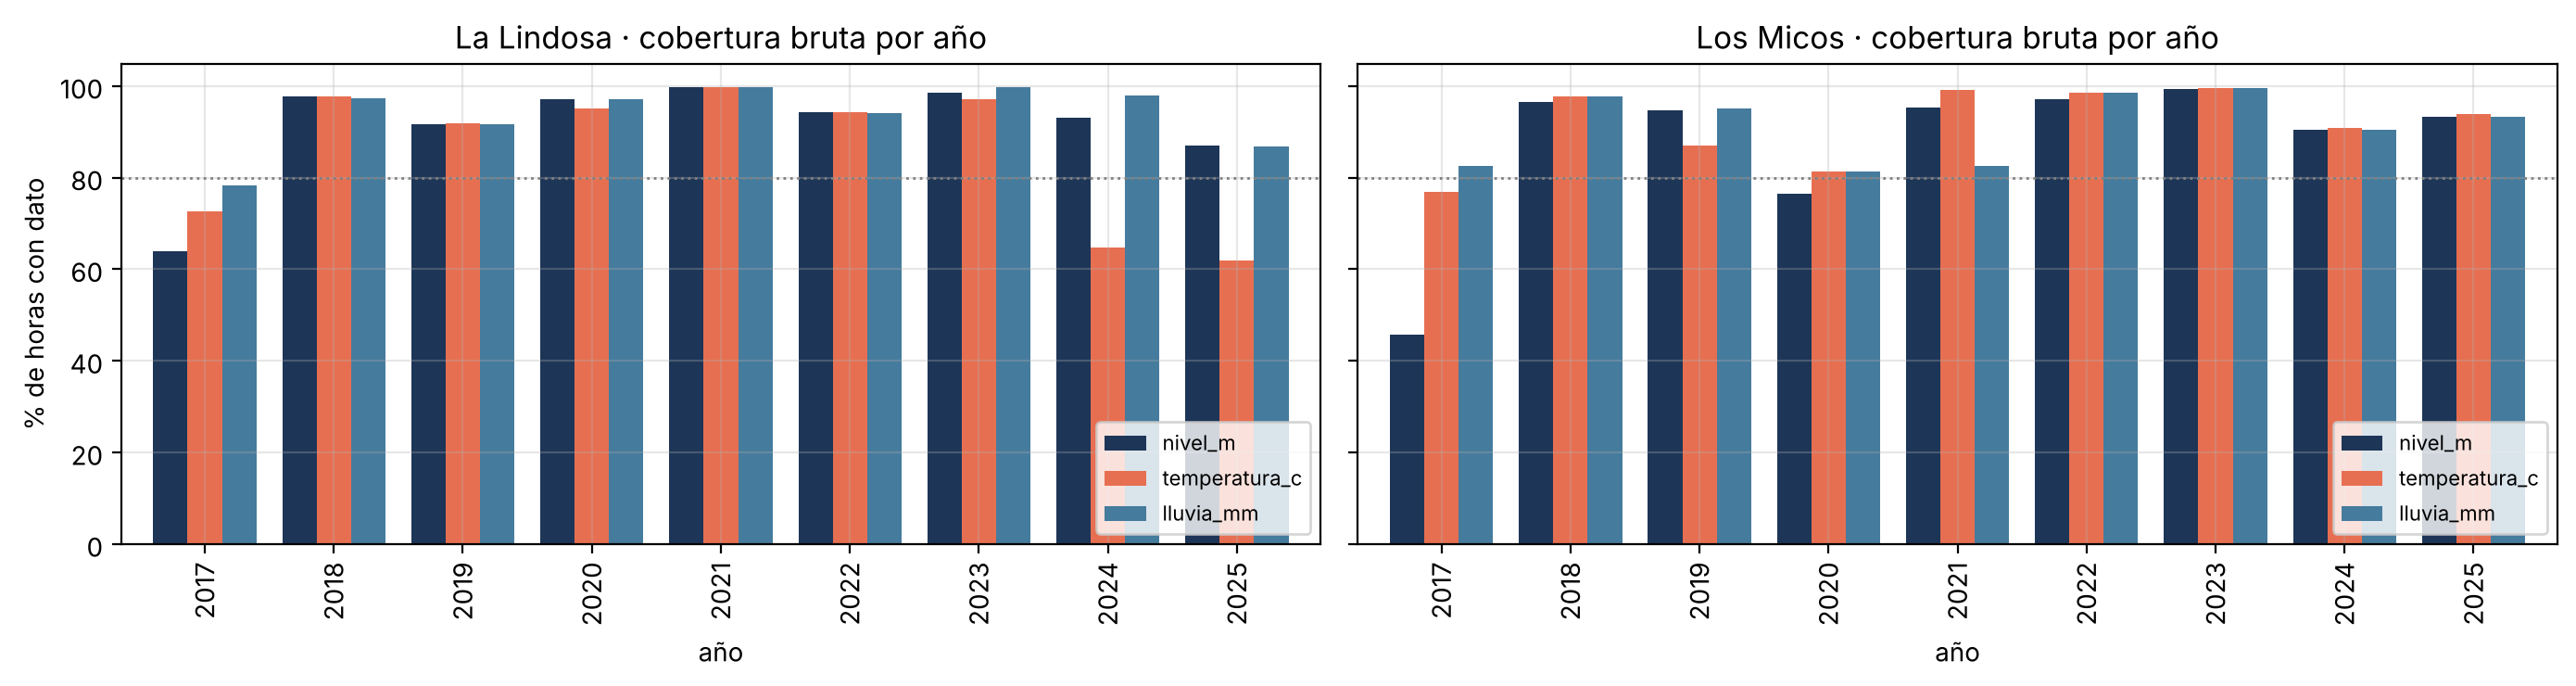

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, (est, h) in zip(axes, horario.items()):
    cob = h[VARIABLES].notna().groupby(h.index.year).mean().mul(100)
    cob.plot(kind="bar", ax=ax, color=["#1d3557", "#e76f51", "#457b9d"], width=0.8)
    ax.set_title(f"{est.replace('_', ' ')} · cobertura bruta por año")
    ax.set_xlabel("año")
    ax.axhline(80, color="grey", ls=":", lw=1)
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("% de horas con dato")
plt.tight_layout()
plt.show()

2017 tiene cobertura baja porque la serie arranca en junio (las horas de enero a junio no existen en la grilla, pero las primeras semanas tienen muchos vacíos). En La Lindosa la temperatura cae a ~63 % en 2024-2025; en Los Micos 2020 tiene la caída del cambio de sistema MAIGRAI → MeerKAD (enero-febrero sin datos) y la lluvia de 2021 un hueco largo.

## 4. Catálogo de huecos (gaps)

Un hueco es una secuencia de horas consecutivas **sin dato** en una variable. Para cada hueco se guarda:

- `inicio` y `fin`: primera y última hora vacía,
- `horas_faltantes`: número de registros horarios perdidos (= duración en horas),
- `categoria`: corto / medio / largo,
- `dato_antes` y `dato_despues`: si hay un dato válido justo antes y justo después (un hueco al principio o al final de la serie no se puede interpolar).

In [6]:
def categoria(horas):
    if horas <= LIMITE_CORTO_H:
        return "corto"
    if horas <= LIMITE_MEDIO_H:
        return "medio"
    return "largo"

def catalogar_huecos(serie):
    vacio = serie.isna()
    # cada vez que se pasa de "con dato" a "vacío" empieza un hueco nuevo
    id_hueco = (vacio != vacio.shift()).cumsum()[vacio]
    if id_hueco.empty:
        return pd.DataFrame()
    tiempos = id_hueco.index.to_series()
    cat = tiempos.groupby(id_hueco.values).agg(inicio="min", fin="max", horas_faltantes="size")
    cat["categoria"] = cat.horas_faltantes.map(categoria)
    cat["dato_antes"] = cat.inicio > serie.index.min()
    cat["dato_despues"] = cat.fin < serie.index.max()
    return cat.reset_index(drop=True)

inventario = {}
for est, h in horario.items():
    partes = []
    for var in VARIABLES:
        c = catalogar_huecos(h[var])
        c.insert(0, "variable", var)
        partes.append(c)
    inventario[est] = pd.concat(partes, ignore_index=True)
    print(f"{est}: {len(inventario[est]):,} huecos catalogados")

inventario["La_Lindosa"].sort_values("horas_faltantes", ascending=False).head(10)

La_Lindosa: 430 huecos catalogados
Los_Micos: 877 huecos catalogados


,variable,inicio,fin,horas_faltantes,categoria,dato_antes,dato_despues
214,temperatura_c,2023-12-21 03:00:00,2024-02-27 05:00:00,1635,largo,True,True
226,temperatura_c,2024-11-09 00:00:00,2024-12-31 23:00:00,1272,largo,True,True
233,temperatura_c,2025-09-05 00:00:00,2025-10-25 23:00:00,1224,largo,True,True
229,temperatura_c,2025-05-02 00:00:00,2025-06-09 23:00:00,936,largo,True,True
232,temperatura_c,2025-06-30 00:00:00,2025-08-06 23:00:00,912,largo,True,True
11,nivel_m,2017-09-05 08:00:00,2017-10-07 16:00:00,777,largo,True,True
174,temperatura_c,2017-09-06 12:00:00,2017-10-07 16:00:00,749,largo,True,True
246,lluvia_mm,2017-09-06 12:00:00,2017-10-07 15:00:00,748,largo,True,True
223,temperatura_c,2024-07-19 00:00:00,2024-08-02 13:00:00,350,largo,True,True
291,lluvia_mm,2019-05-09 05:00:00,2019-05-23 11:00:00,343,largo,True,True


## 5. Resumen de huecos por categoría

Dos formas de mirar lo mismo: **cuántos huecos** hay de cada tipo y **cuántas horas** se pierden en cada tipo. Normalmente hay muchos huecos cortos, pero la mayoría de las horas perdidas está en unos pocos huecos largos.

In [7]:
orden = ["corto", "medio", "largo"]
for est, inv in inventario.items():
    resumen = inv.pivot_table(index="variable", columns="categoria", values="horas_faltantes",
                              aggfunc=["count", "sum"], fill_value=0)
    resumen = resumen.reindex(columns=pd.MultiIndex.from_product([["count", "sum"], orden]), fill_value=0)
    resumen.columns = [f"{'n.º huecos' if a == 'count' else 'horas'} {c}" for a, c in resumen.columns]
    print(est)
    display(resumen.reindex(VARIABLES))

La_Lindosa


,n.º huecos corto,n.º huecos medio,n.º huecos largo,horas corto,horas medio,horas largo
variable,,,,,,
nivel_m,81,45,44,164,669,4402
temperatura_c,29,8,33,49,80,9673
lluvia_mm,131,24,35,200,335,3577


Los_Micos


,n.º huecos corto,n.º huecos medio,n.º huecos largo,horas corto,horas medio,horas largo
variable,,,,,,
nivel_m,447,82,24,1033,926,5515
temperatura_c,52,72,24,154,826,4640
lluvia_mm,79,74,23,202,887,5100


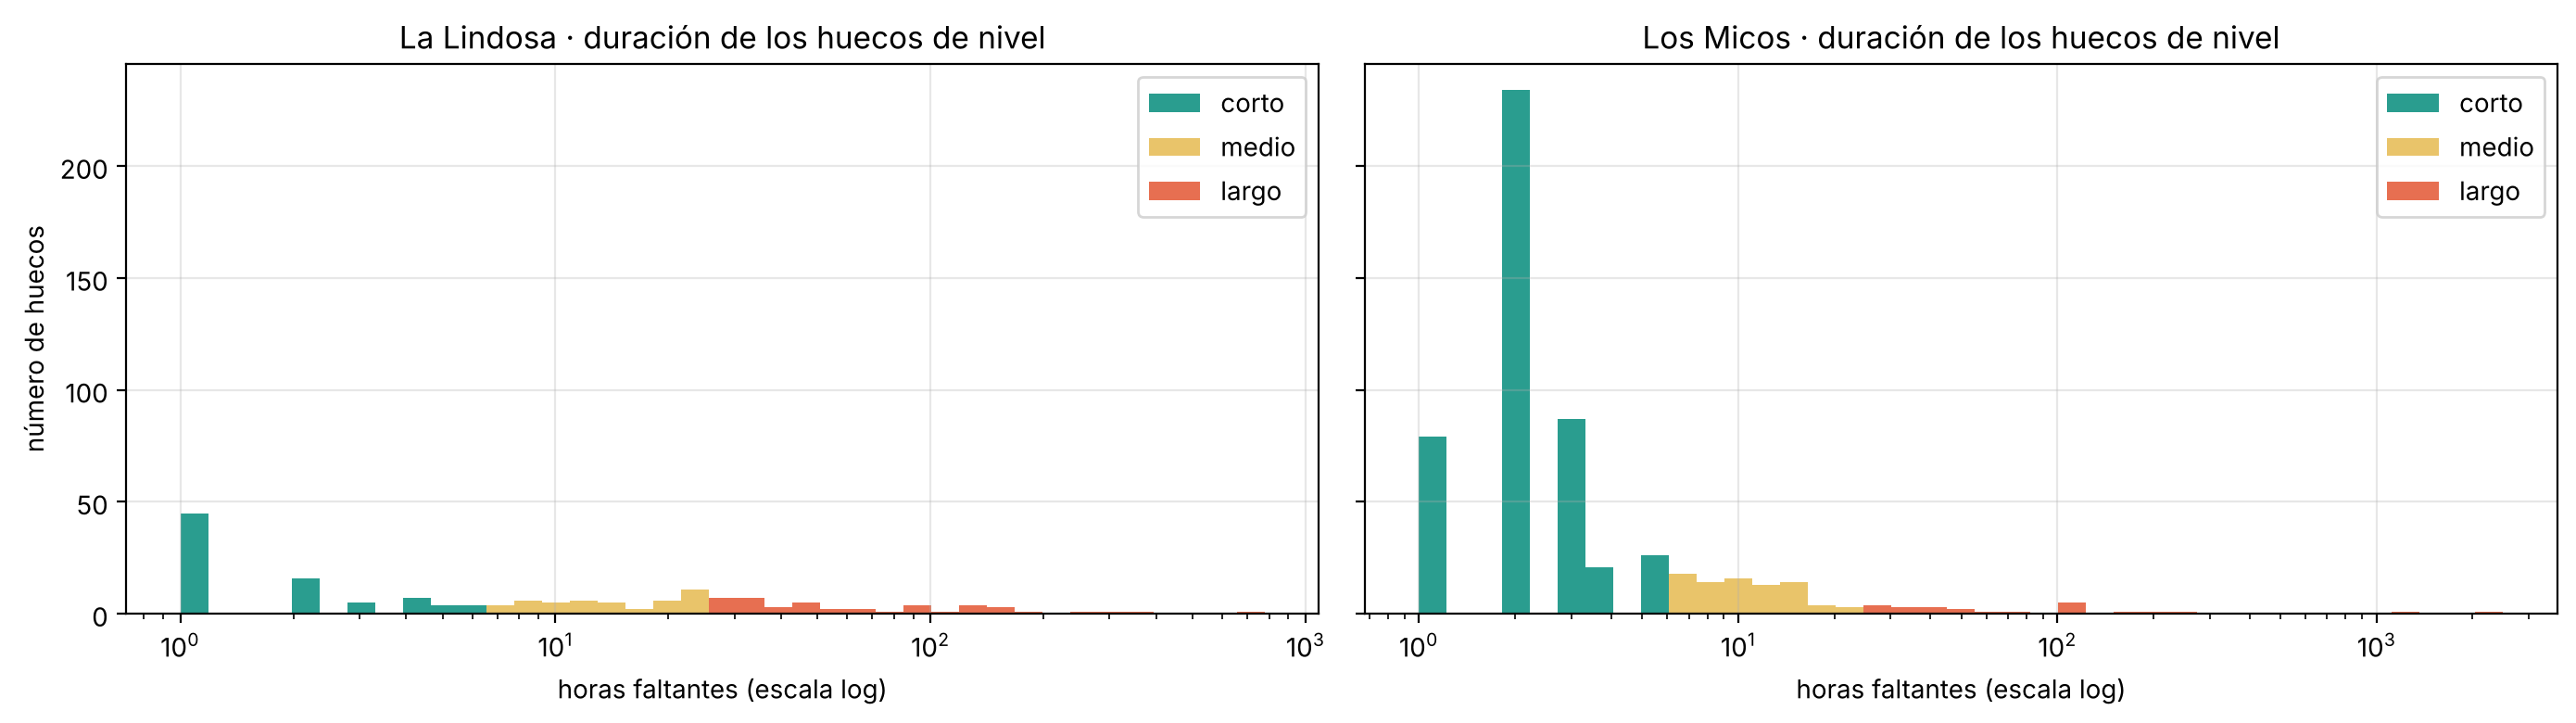

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
colores = {"corto": "#2a9d8f", "medio": "#e9c46a", "largo": "#e76f51"}
for ax, (est, inv) in zip(axes, inventario.items()):
    nv = inv[inv.variable == "nivel_m"]
    bins = np.logspace(0, np.log10(nv.horas_faltantes.max() + 1), 40)
    for cat in orden:
        ax.hist(nv.loc[nv.categoria == cat, "horas_faltantes"], bins=bins, color=colores[cat], label=cat)
    ax.set_xscale("log")
    ax.set_title(f"{est.replace('_', ' ')} · duración de los huecos de nivel")
    ax.set_xlabel("horas faltantes (escala log)")
    ax.legend()
axes[0].set_ylabel("número de huecos")
plt.tight_layout()
plt.show()

### Los huecos largos de nivel

Estos son los que más importan para el modelado: no se pueden rellenar con confianza y conviene excluirlos de las ventanas de entrenamiento.

In [9]:
for est, inv in inventario.items():
    largos = inv[(inv.variable == "nivel_m") & (inv.categoria == "largo")].copy()
    largos["días"] = largos.horas_faltantes / 24
    print(f"{est}: {len(largos)} huecos largos de nivel, {largos.horas_faltantes.sum():,} horas en total")
    display(largos.sort_values("horas_faltantes", ascending=False).head(8)[["inicio", "fin", "días"]])

La_Lindosa: 44 huecos largos de nivel, 4,402 horas en total


,inicio,fin,días
11,2017-09-05 08:00:00,2017-10-07 16:00:00,32.38
14,2019-05-09 05:00:00,2019-05-23 11:00:00,14.29
43,2022-01-19 08:00:00,2022-01-31 08:00:00,12.04
8,2017-07-25 14:00:00,2017-08-04 15:00:00,10.08
96,2024-02-16 14:00:00,2024-02-24 07:00:00,7.75
123,2025-06-02 19:00:00,2025-06-09 09:00:00,6.62
13,2018-02-24 08:00:00,2018-03-02 16:00:00,6.38
3,2017-07-06 11:00:00,2017-07-12 08:00:00,5.92


Los_Micos: 24 huecos largos de nivel, 5,515 horas en total


,inicio,fin,días
0,2017-06-23 17:00:00,2017-10-05 13:00:00,103.88
17,2020-01-01 00:00:00,2020-02-24 17:00:00,54.75
6,2019-05-25 08:00:00,2019-06-04 07:00:00,10.00
457,2024-06-16 18:00:00,2024-06-24 11:00:00,7.75
4,2018-02-24 09:00:00,2018-03-02 15:00:00,6.29
166,2020-10-30 06:00:00,2020-11-04 08:00:00,5.12
447,2024-05-17 15:00:00,2024-05-22 14:00:00,5.00
419,2024-03-27 08:00:00,2024-03-31 23:00:00,4.67


## 6. Mapa de faltantes

Cada celda es un mes; el color indica el porcentaje de horas **sin** nivel. Permite ver de un vistazo dónde están los huecos.

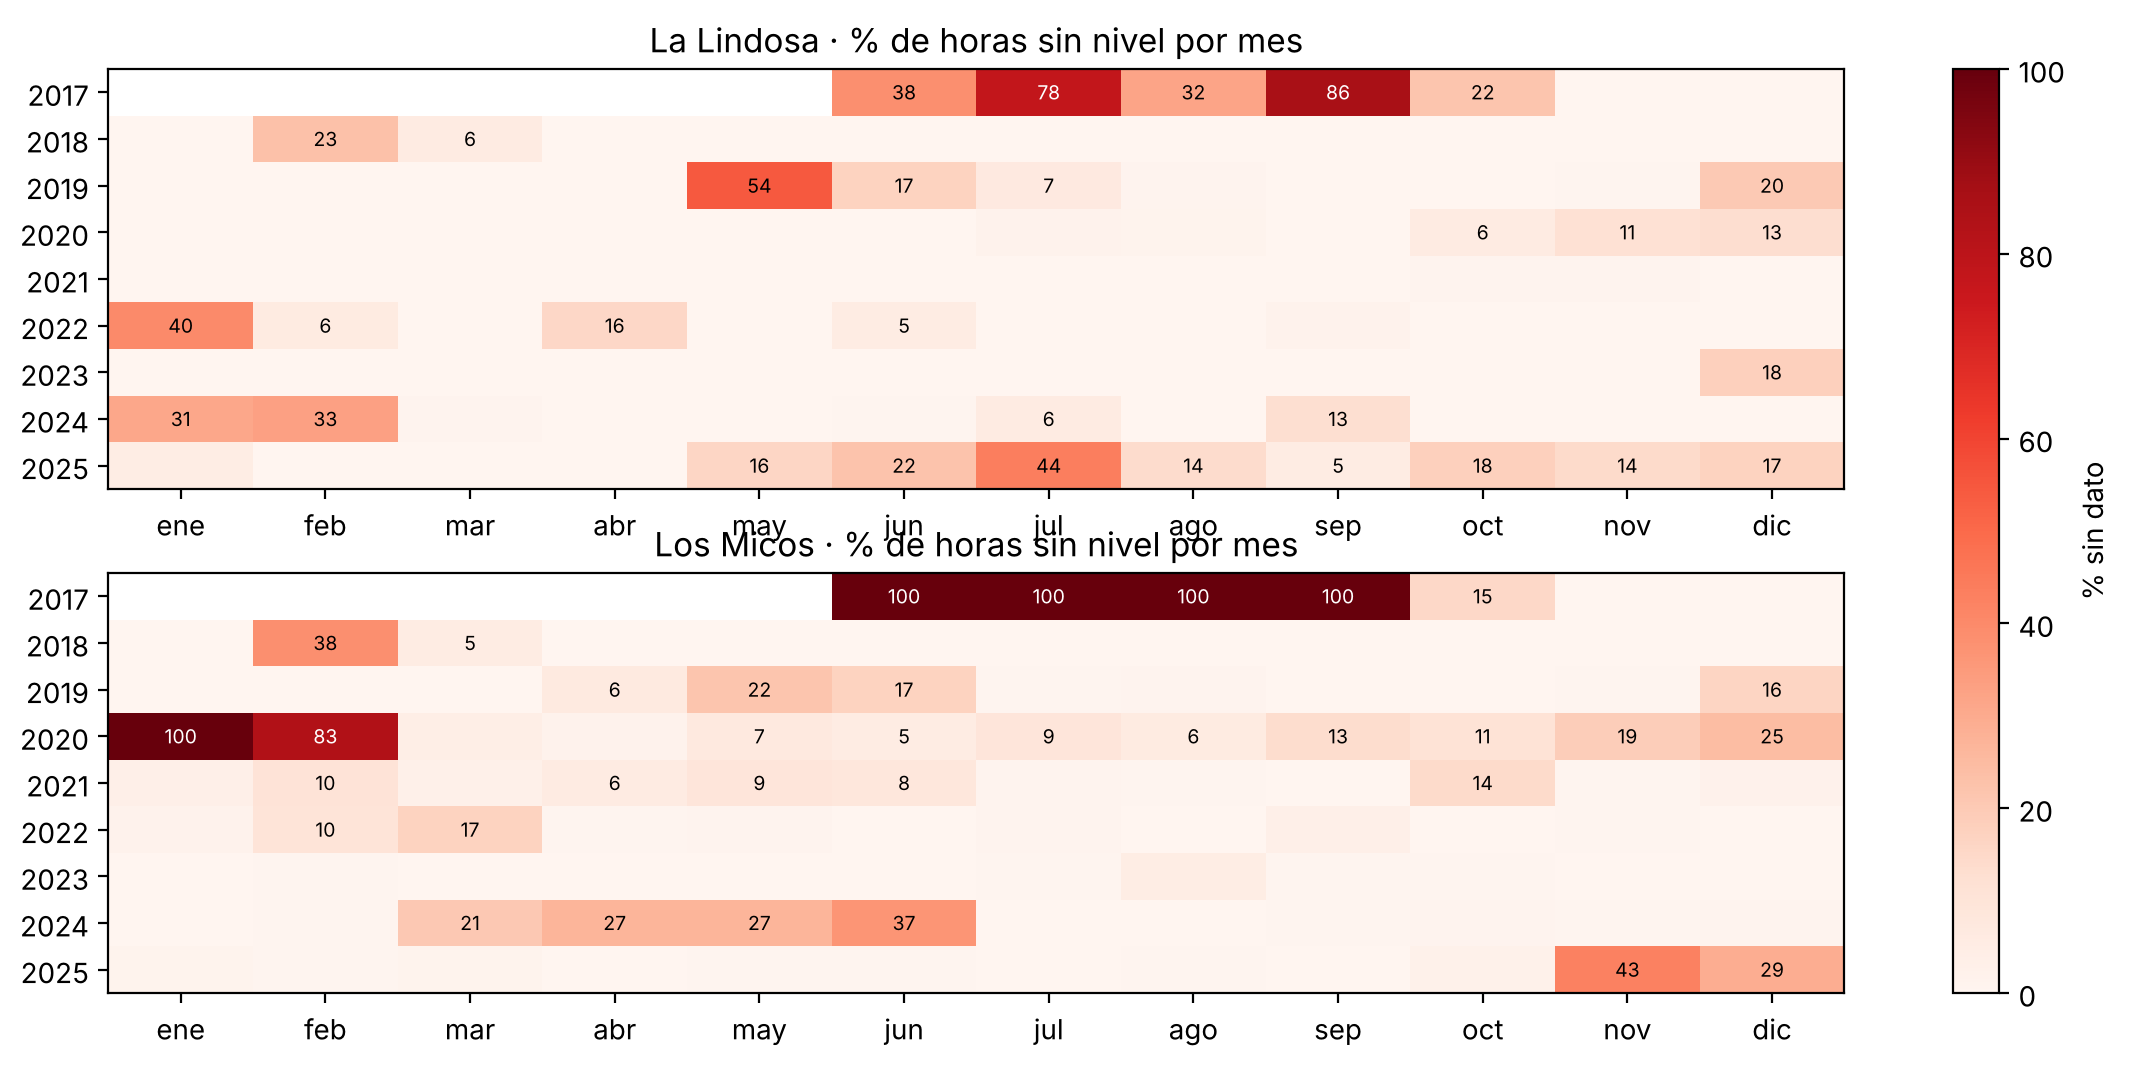

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6))
for ax, (est, h) in zip(axes, horario.items()):
    falt = h.nivel_m.isna().groupby([h.index.year, h.index.month]).mean().mul(100).unstack()
    im = ax.imshow(falt.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
    ax.set_yticks(range(len(falt.index)), falt.index)
    ax.set_xticks(range(12), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
    ax.set_title(f"{est.replace('_', ' ')} · % de horas sin nivel por mes")
    ax.grid(False)
    for (i, j), v in np.ndenumerate(falt.values):
        if not np.isnan(v) and v >= 5:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 60 else "black")
fig.colorbar(im, ax=axes, label="% sin dato")
plt.show()

## 7. Guardar el inventario

Se crea la carpeta `data/clean/<estación>/` y se guarda el catálogo. El notebook 03 usa las mismas reglas para decidir el método de relleno de cada hueco.

In [11]:
for est, inv in inventario.items():
    carpeta = CLEAN / est
    carpeta.mkdir(parents=True, exist_ok=True)
    salida = inv.copy()
    salida["inicio"] = salida.inicio.dt.strftime("%Y-%m-%d %H:%M")
    salida["fin"] = salida.fin.dt.strftime("%Y-%m-%d %H:%M")
    ruta = carpeta / f"{est}_inventario_huecos.csv"
    salida.to_csv(ruta, index=False)
    print(f"Guardado {ruta.relative_to(RAIZ)} ({len(salida):,} huecos)")

Guardado data/clean/La_Lindosa/La_Lindosa_inventario_huecos.csv (430 huecos)
Guardado data/clean/Los_Micos/Los_Micos_inventario_huecos.csv (877 huecos)


**Conclusión del ítem C:** las dos estaciones tienen frecuencia dominante horaria tras el notebook 01 y una cobertura bruta de nivel del 90-93 %. Los huecos **cortos** son los más numerosos, pero las horas perdidas se concentran en pocos huecos **largos** (de días a meses): en el nivel, sobre todo en 2017-2019 (años MAIGRAI) y, en Los Micos, al inicio de la serie y en enero-febrero de 2020 (cambio de sistema MAIGRAI → MeerKAD). En La Lindosa la temperatura tiene varios huecos largos en 2024-2025. Esta clasificación define el método de relleno del notebook 03.